# Project 01: House Price Prediction System
**Machine Learning & AI BootCamp Portfolio Milestone**  
*Instructor: Fahd*

---

## 🏠 Project Overview & Business Case
Real estate valuation has traditionally relied on manual appraisals, which are slow, subjective, and prone to human bias. In this capstone project, you will build an automated, data-driven **House Price Prediction System** capable of accurately estimating property values based on architectural dimensions, location, build quality, and property amenities.

### Objectives:
1. Conduct thorough Exploratory Data Analysis (EDA) on residential sales records (`house_price_prediction_data.csv`).
2. Engineer high-impact domain features (age, luxury indicators, space ratios).
3. Construct a production-grade Scikit-Learn preprocessing pipeline preventing data leakage.
4. Train and benchmark multiple regression architectures:
   - Baseline Mean Model (`DummyRegressor`)
   - Ordinary Least Squares Multiple Linear Regression
   - Polynomial Feature Regression
   - Regularized Regression (Ridge & Lasso)
5. Perform hyperparameter tuning to find optimal regularization strength $\alpha$.
6. Evaluate model performance using MAE, RMSE, and $R^2$, and extract top market value drivers.


---
## Student Information
- **Student Name:** *[Sabrin Alam]*
- **Batch:** *[MBL-2]*
- **Date:** *[31/10/2026]*


In [33]:
# Run this cell first to import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Project libraries successfully imported!")


Project libraries successfully imported!
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


---
## Step 1: Data Ingestion & Initial Inspection
1. Load `house_price_prediction_data.csv` into a DataFrame named `df`.
2. Inspect the first 5 rows and verify the shape and data types.
3. Check for missing values across all columns.


In [34]:
# TODO 1.1: Load dataset and inspect first 5 rows
df = pd.read_csv("/kaggle/input/datasets/sabrinalom1/house-prediction-dataset/house_price_prediction_data - house_price_prediction_data.csv")

print("Shape (rows, columns):", df.shape)
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

Shape (rows, columns): (2500, 13)


,property_id,sqft_living,bedrooms,bathrooms,lot_size_sqft,floors,waterfront,view_score,condition_rating,grade_score,yr_built,neighborhood,price_usd
0,PROP-2001,1180,3,1.00,5650,1.0,0,0,3,7,1955,Suburbs,321950
1,PROP-2002,2570,3,2.25,7242,2.0,0,0,3,7,1951,Northside,538000
2,PROP-2003,770,2,1.00,10000,1.0,0,0,3,6,1933,Downtown,280000
3,PROP-2004,1960,4,3.00,5000,1.0,0,0,5,7,1965,WestEnd,604000
4,PROP-2005,1680,3,2.00,8080,1.0,0,0,3,8,1987,Suburbs,510000



Data types:
property_id          object
sqft_living           int64
bedrooms              int64
bathrooms           float64
lot_size_sqft         int64
floors              float64
waterfront            int64
view_score            int64
condition_rating      int64
grade_score           int64
yr_built              int64
neighborhood         object
price_usd             int64
dtype: object

Missing values per column:
property_id         0
sqft_living         0
bedrooms            0
bathrooms           0
lot_size_sqft       0
floors              0
waterfront          0
view_score          0
condition_rating    0
grade_score         0
yr_built            0
neighborhood        0
price_usd           0
dtype: int64


---
## Step 2: Exploratory Data Analysis (EDA)
1. Examine the summary statistics of `price_usd`.
2. Plot a histogram with KDE of `price_usd` to observe distribution shape and skewness.
3. Plot a boxplot comparing prices across different `neighborhood` categories.


count    2.500000e+03
mean     5.893224e+05
std      2.723450e+05
min      2.500000e+05
25%      4.090000e+05
50%      5.020000e+05
75%      6.440000e+05
max      1.579500e+06
Name: price_usd, dtype: float64

Skewness of price_usd: 1.69


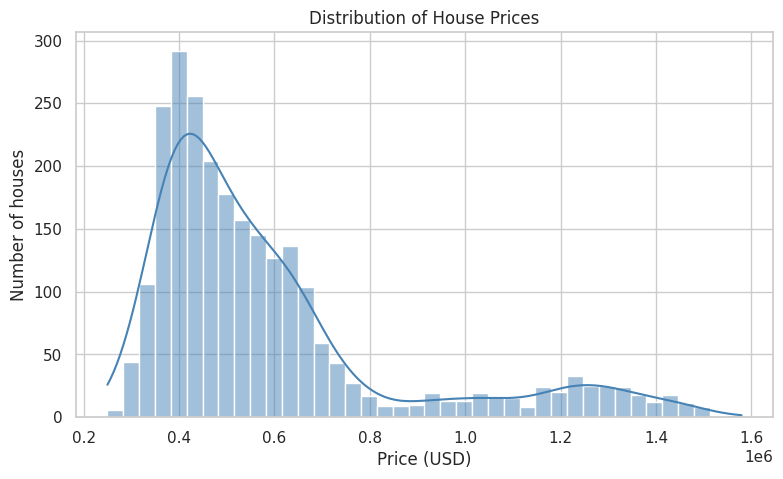

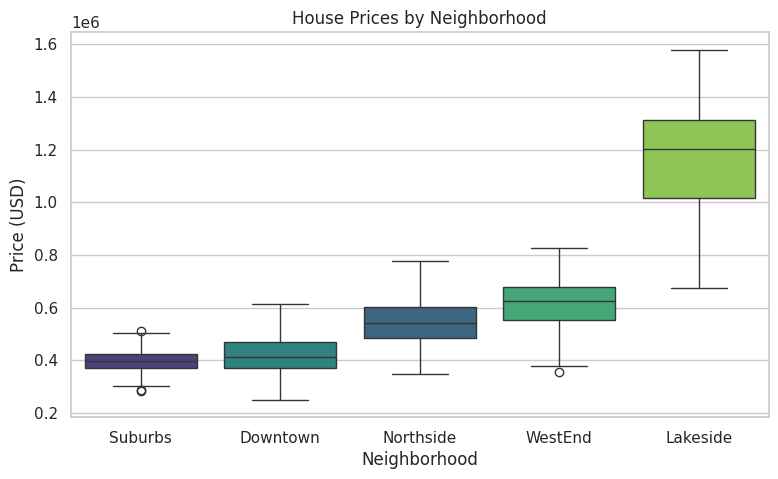

neighborhood
Suburbs       398000.0
Downtown      414250.0
Northside     541500.0
WestEnd       626000.0
Lakeside     1201000.0
Name: price_usd, dtype: float64


In [35]:
# TODO 2.1: Price distribution plot & summary statistics
print(df['price_usd'].describe())
print("\nSkewness of price_usd:", round(df['price_usd'].skew(), 2))

plt.figure(figsize=(9, 5))
sns.histplot(df['price_usd'], kde=True, bins=40, color='steelblue')
plt.title("Distribution of House Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of houses")
plt.show()
# TODO 2.2: Price vs. Neighborhood boxplot
order = df.groupby('neighborhood')['price_usd'].median().sort_values().index

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='neighborhood', y='price_usd', order=order, palette='viridis', hue='neighborhood', legend=False)
plt.title("House Prices by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Price (USD)")
plt.show()

print(df.groupby('neighborhood')['price_usd'].median().sort_values())



# Step 2: EDA (Exploratory Data Analysis)
# Observations:
1. House prices are right-skewed. Most houses are cheap, but a few houses are very expensive.
2. The median price is $502K, but the average price is $589K. Some expensive houses increase the average.
3. Lakeside has the highest house prices (around $1.2M).
4. Suburbs and Downtown have the lowest house prices (around $400K).
5. So, the location of a house affects its price.

---
## Step 3: Domain Feature Engineering
In real estate analytics, raw features alone do not tell the whole story.
1. Create `property_age`: Number of years since construction relative to `2024` ($2024 - \text{yr\_built}$).
2. Create `bath_to_bed_ratio`: Ratio of bathrooms to bedrooms ($\frac{\text{bathrooms}}{\text{bedrooms}}$).
3. Create a binary indicator `is_luxury`: $1$ if `waterfront == 1` OR `grade_score >= 10`, else $0$.
4. Display the first 5 rows of these newly created features.


In [36]:
# TODO 3.1: Create property_age, bath_to_bed_ratio, and is_luxury
df['property_age'] = 2024 - df['yr_built']
df['bath_to_bed_ratio'] = df['bathrooms'] / df['bedrooms']
df['is_luxury'] = ((df['waterfront'] == 1) | (df['grade_score'] >= 10)).astype(int)

# TODO 3.2: Display first 5 rows of engineered features
display(df[['yr_built', 'property_age', 'bathrooms', 'bedrooms', 'bath_to_bed_ratio',
            'waterfront', 'grade_score', 'is_luxury']].head())

print("Share of luxury homes:", round(df['is_luxury'].mean() * 100, 1), "%")
print("Average price -> luxury vs non-luxury:")
print(df.groupby('is_luxury')['price_usd'].mean().round(0))




,yr_built,property_age,bathrooms,bedrooms,bath_to_bed_ratio,waterfront,grade_score,is_luxury
0,1955,69,1.00,3,0.333333,0,7,0
1,1951,73,2.25,3,0.750000,0,7,0
2,1933,91,1.00,2,0.500000,0,6,0
3,1965,59,3.00,4,0.750000,0,7,0
4,1987,37,2.00,3,0.666667,0,8,0


Share of luxury homes: 12.8 %
Average price -> luxury vs non-luxury:
is_luxury
0     497392.0
1    1213360.0
Name: price_usd, dtype: float64


---
## Step 4: Preprocessing Pipeline Construction
1. Define feature matrix `X` and target `y` (`price_usd`). Drop `property_id` and `price_usd` from `X`.
2. Identify numerical columns and categorical columns:
   - Numerical: `['sqft_living', 'bedrooms', 'bathrooms', 'lot_size_sqft', 'floors', 'waterfront', 'view_score', 'condition_rating', 'grade_score', 'property_age', 'bath_to_bed_ratio', 'is_luxury']`
   - Categorical: `['neighborhood']`
3. Build a `ColumnTransformer` named `preprocessor`:
   - Standardize numerical features with `StandardScaler()`.
   - One-hot encode `neighborhood` with `OneHotEncoder(drop='first', sparse_output=False)`.
4. Perform an **80/20 train-test split** using `train_test_split(X, y, test_size=0.20, random_state=42)`.


In [37]:
# TODO 4.1: Define X and y
X = df.drop(columns=['property_id', 'price_usd'])
y = df['price_usd']
print("X shape:", X.shape, "| y shape:", y.shape)

# TODO 4.2: Build ColumnTransformer preprocessor
num_cols = ['sqft_living', 'bedrooms', 'bathrooms', 'lot_size_sqft', 'floors', 'waterfront',
            'view_score', 'condition_rating', 'grade_score', 'property_age',
            'bath_to_bed_ratio', 'is_luxury']
cat_cols = ['neighborhood']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
])

# TODO 4.3: Perform 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])



X shape: (2500, 14) | y shape: (2500,)
Train size: 2000 | Test size: 500


---
## Step 5: Model Training & Experimentation
Train 4 distinct regression architectures inside clean Scikit-Learn pipelines:
1. **Model 1: Baseline Dummy Regressor** (`DummyRegressor(strategy='mean')`)
2. **Model 2: OLS Linear Regression** (`LinearRegression()`)
3. **Model 3: Ridge Regression** (`Ridge(alpha=10.0)`)
4. **Model 4: Lasso Regression** (`Lasso(alpha=100.0)`)


In [38]:
# TODO 5.1: Build and fit Pipeline for Model 1 (Dummy Baseline)
pipe_dummy = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DummyRegressor(strategy='mean'))
])
pipe_dummy.fit(X_train, y_train)


# TODO 5.2: Build and fit Pipeline for Model 2 (Linear Regression)
pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
pipe_lr.fit(X_train, y_train)


# TODO 5.3: Build and fit Pipeline for Model 3 (Ridge Regression)
pipe_ridge = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=10.0))
])
pipe_ridge.fit(X_train, y_train)


# TODO 5.4: Build and fit Pipeline for Model 4 (Lasso Regression)
pipe_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=100.0))
])
pipe_lasso.fit(X_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['sqft_living', 'bedrooms',
                                                   'bathrooms', 'lot_size_sqft',
                                                   'floors', 'waterfront',
                                                   'view_score',
                                                   'condition_rating',
                                                   'grade_score',
                                                   'property_age',
                                                   'bath_to_bed_ratio',
                                                   'is_luxury']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['neighborhood'])])),
                ('regressor', Lasso(alpha=100.0))])

---
## Step 6: Model Evaluation & Comparative Benchmark
1. For each model, generate predictions on the holdout test set (`X_test`).
2. Calculate **MAE**, **RMSE**, and **$R^2$ Score** on the test set.
3. Consolidate results into a clean comparative DataFrame named `benchmark_df` and display it.


In [39]:
# TODO 6.1: Compute test metrics for all 4 models and build benchmark_df
models = {
    'Dummy (Mean Baseline)': pipe_dummy,
    'Linear Regression': pipe_lr,
    'Ridge (alpha=10)': pipe_ridge,
    'Lasso (alpha=100)': pipe_lasso
}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

benchmark_df = pd.DataFrame(rows).set_index('Model').round(3)
display(benchmark_df)



,MAE,RMSE,R2
Model,,,
Dummy (Mean Baseline),197459.064,279889.862,-0.001
Linear Regression,21912.163,27734.481,0.990
Ridge (alpha=10),22135.191,28044.705,0.990
Lasso (alpha=100),21991.871,27853.799,0.990


# Step 6: Model Comparison
Observations:
1. The Dummy model is very poor because it only predicts the average house price.
2. Linear, Ridge, and Lasso models perform much better, with an R² of 0.99.
3. All three models have almost the same results.
4. Linear Regression performs slightly better than the others.
5. So, all three models make very accurate predictions.

---
## Step 7: Hyperparameter Tuning for Regularization
Use `GridSearchCV` on the Ridge pipeline to find the optimal regularization strength $\alpha$ from:
`param_grid = {'regressor__alpha': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]}`.
1. Run 5-fold cross-validation optimizing for negative root mean squared error (`scoring='neg_root_mean_squared_error'`).
2. Print the best alpha value and the best cross-validation score.


In [40]:
# TODO 7.1: Setup and run GridSearchCV on Ridge pipeline
param_grid = {'regressor__alpha': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]}

grid = GridSearchCV(
    estimator=pipe_ridge,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid.fit(X_train, y_train)


# TODO 7.2: Print best alpha and best score
print("Best alpha:", grid.best_params_['regressor__alpha'])
print("Best CV RMSE: {:,.2f}".format(-grid.best_score_))

cv_results = pd.DataFrame({
    'alpha': param_grid['regressor__alpha'],
    'CV RMSE': -grid.cv_results_['mean_test_score']
}).round(2)
display(cv_results)

# Test performance of the tuned model
best_model = grid.best_estimator_
pred_best = best_model.predict(X_test)
print("\nTuned Ridge on test set -> MAE: {:,.0f} | RMSE: {:,.0f} | R2: {:.4f}".format(
    mean_absolute_error(y_test, pred_best),
    np.sqrt(mean_squared_error(y_test, pred_best)),
    r2_score(y_test, pred_best)))


Best alpha: 0.1
Best CV RMSE: 29,357.27


,alpha,CV RMSE
0,0.1,29357.27
1,1.0,29371.63
2,5.0,29537.36
3,10.0,29757.60
4,50.0,31088.68
5,100.0,32487.74
6,500.0,40920.31



Tuned Ridge on test set -> MAE: 21,911 | RMSE: 27,734 | R2: 0.9902


# Step 7: Hyperparameter Tuning
Observations:
- The best alpha value is 0.1.
- When alpha increases, the prediction error also increases.
- The RMSE increases from $29.4K to $40.9K.
- This means the model works better with less regularization.
- The tuned Ridge model gets an R² score of 0.99 on the test data.

---
## Step 8: Residual Analysis & Business Insights
1. Generate residuals ($y_{\text{test}} - \hat{y}_{\text{pred}}$) for your best tuned model.
2. Plot Actual vs. Predicted prices and the Residual plot.
3. Extract and plot the top 5 most influential positive and negative coefficients driving home valuation.


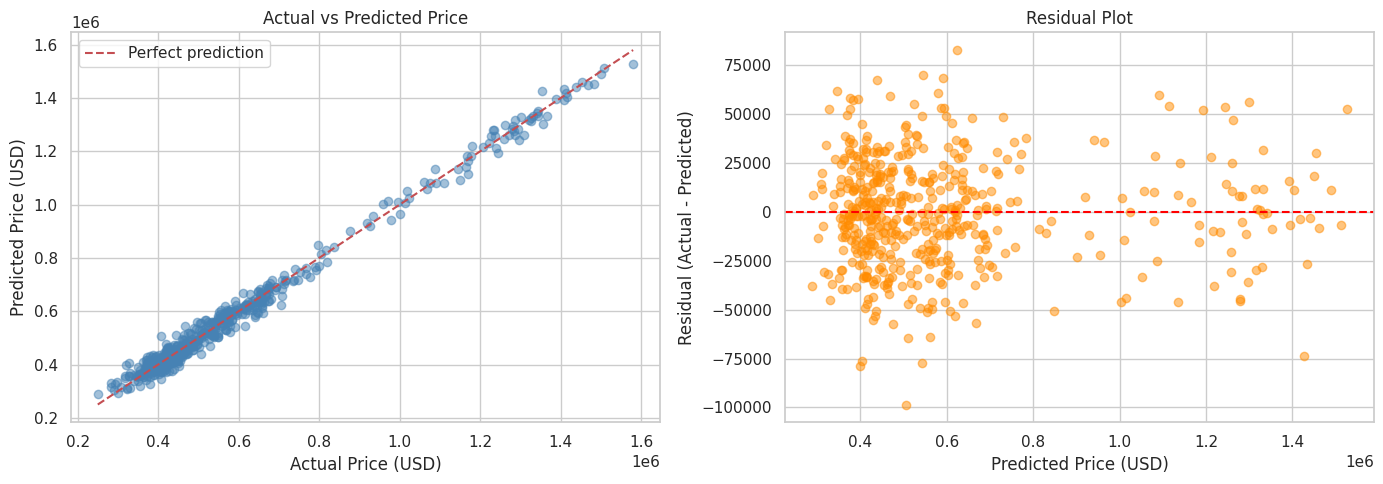

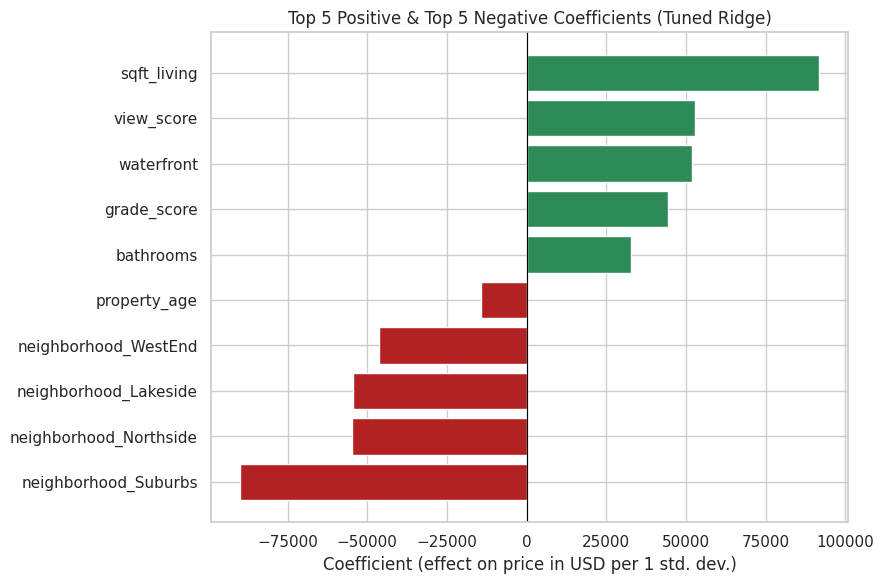

sqft_living               91850.0
view_score                52940.0
waterfront                51856.0
grade_score               44367.0
bathrooms                 32672.0
bedrooms                  19297.0
condition_rating          16837.0
lot_size_sqft             14320.0
is_luxury                  1876.0
bath_to_bed_ratio         -7541.0
floors                    -8251.0
property_age             -14404.0
neighborhood_WestEnd     -46188.0
neighborhood_Lakeside    -54434.0
neighborhood_Northside   -54798.0
neighborhood_Suburbs     -89894.0
dtype: float64


In [41]:
# TODO 8.1: Plot Actual vs Predicted & Residuals for best model
residuals = y_test - pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, pred_best, alpha=0.5, color='steelblue')
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_title("Actual vs Predicted Price")
axes[0].set_xlabel("Actual Price (USD)")
axes[0].set_ylabel("Predicted Price (USD)")
axes[0].legend()

# Residual plot
axes[1].scatter(pred_best, residuals, alpha=0.5, color='darkorange')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted Price (USD)")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()


# TODO 8.2: Plot Top Feature Coefficients
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
coefs = pd.Series(best_model.named_steps['regressor'].coef_, index=feature_names)
coefs.index = [name.split('__')[1] for name in coefs.index]   # remove 'num__' / 'cat__' prefix

top_pos = coefs.sort_values(ascending=False).head(5)
top_neg = coefs.sort_values().head(5)
top_10 = pd.concat([top_pos, top_neg]).sort_values()

plt.figure(figsize=(9, 6))
colors = ['firebrick' if v < 0 else 'seagreen' for v in top_10]
plt.barh(top_10.index, top_10.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Top 5 Positive & Top 5 Negative Coefficients (Tuned Ridge)")
plt.xlabel("Coefficient (effect on price in USD per 1 std. dev.)")
plt.tight_layout()
plt.show()

print(coefs.sort_values(ascending=False).round(0))




# Step 8: Residuals and Business Insights
Observations:
- In the Actual vs Predicted plot, most points are close to the red line. This means the model predicts prices well.
- In the residual plot, the points are spread around zero. This means the model fits the data well.
- House size, view, waterfront, and building quality increase house prices.
- Older houses usually have lower prices.
- The neighborhood results are compared with Downtown.
- A negative coefficient means the house price is lower than Downtown, when other features are the same.
- Conclusion: House size, quality, view, and waterfront are the main factors that affect house prices.

---
### 🏆 Capstone Project Completed!
You have engineered an end-to-end Machine Learning valuation system:
- Built a leak-free preprocessing pipeline handling mixed data types.
- Compared baseline, linear, and regularized models.
- Tuned hyperparameters using cross-validation.
- Uncovered key business drivers of residential real estate valuation!
